# CS215 Open Project — MPI vs Health Indicators
## Exploratory analysis of the NFHS-5 district dataset

**Dataset:** `MPI_vs_Health_Indicators.xlsx`
**Rows:** 707 districts | **Columns:** 11 (District, State, MPI, 8 health indicators)  
**Research question:** How is district-level multidimensional poverty (MPI) associated with selected health indicators?

**Note:** Observational, district-level analysis. Correlation is not causation, and district averages do not describe every individual in a district.

## 1. Load the dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, linregress

df_raw = pd.read_excel("./data/clean/MPI vs Health Indicators.xlsx")
print("Loaded: MPI vs Health Indicators.xlsx")
print("Dataset shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame("Data type"))

Loaded: MPI vs Health Indicators.xlsx
Dataset shape: (707, 11)


,District,State,NFHS-5 2019-21 MPI,Population living in households that use an improved sanitation facility2 %,Women age 15-24 years who use hygienic methods of protection during their menstrual period5 %,Children age 12-23 months fully vaccinated based on information from vaccination card only12 %,"Total children age 6-23 months receiving an adequate diet16, 17 %",All women age 15-49 years who are anaemic22 %,Men age 15 years and above wih high or very high >140 mg/dl Blood sugar level or taking medicine to control blood sugar level23 %,Women age 15 years and above who use any kind of tobacco %,Men age 15 years and above who consume alcohol %
0,Nicobars,Andaman & Nicobar Islands,0.013,83.45,100.00,94.1,18.70,38.30,15.39,63.46,64.49
1,North & Middle Andaman,Andaman & Nicobar Islands,0.019,86.38,100.00,NaN,5.90,62.07,18.28,46.77,45.26
2,South Andamans,Andaman & Nicobar Islands,0.004,89.33,98.19,96.6,23.49,57.66,18.10,19.60,32.81
3,Anantapur,Andhra Pradesh,0.027,71.25,95.01,96.6,2.91,50.45,16.75,5.03,16.84
4,Chittoor,Andhra Pradesh,0.022,74.62,94.66,87.5,5.96,51.80,22.42,4.30,18.30


,Data type
District,object
State,object
NFHS-5 2019-21 MPI,float64
Population living in households that use an improved sanitation facility2 %,float64
Women age 15-24 years who use hygienic methods of protection during their menstrual period5 %,float64
Children age 12-23 months fully vaccinated based on information from vaccination card only12 %,float64
"Total children age 6-23 months receiving an adequate diet16, 17 %",float64
All women age 15-49 years who are anaemic22 %,float64
Men age 15 years and above wih high or very high >140 mg/dl Blood sugar level or taking medicine to control blood sugar level23 %,float64
Women age 15 years and above who use any kind of tobacco %,float64


## 2. Data checks and cleaning

The file has 707 rows and 11 columns: `District`, `State`, the MPI, and eight health indicators (all percentages). All numeric columns are already stored as numbers; `pd.to_numeric` below is only a safeguard.

Missing values: 22 in the vaccination indicator and 1 in the adequate-diet indicator. No rows are imputed. Correlations and regressions use complete cases for each pair, so the sample size differs slightly for those two indicators.

In [2]:
df = df_raw.copy()
MPI_COL = df.columns[2]           
HEALTH_COLS = list(df.columns[3:])

for col in [MPI_COL] + HEALTH_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

SHORT = dict(zip(HEALTH_COLS, [
    "Improved sanitation",
    "Menstrual hygiene",
    "Full vaccination (card)",
    "Adequate diet (6-23 mo)",
    "Anaemia (women 15-49)",
    "High blood sugar (men)",
    "Tobacco use (women)",
    "Alcohol use (men)",
]))

print("Missing values:")
display(df[[MPI_COL] + HEALTH_COLS].isna().sum().rename(index=SHORT).to_frame("Missing"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate State-District pairs:", df.duplicated(["State", "District"]).sum())

Missing values:


,Missing
NFHS-5 2019-21 MPI,0
Improved sanitation,0
Menstrual hygiene,0
Full vaccination (card),22
Adequate diet (6-23 mo),1
Anaemia (women 15-49),0
High blood sugar (men),0
Tobacco use (women),0
Alcohol use (men),0


Exact duplicate rows: 0
Duplicate State-District pairs: 0


## 3. Descriptive statistics

MPI ranges from 0.000 to 0.285 (mean about 0.065). Health indicators are percentages at district level; these are district values, not population-weighted national estimates.

In [3]:
display(df[[MPI_COL] + HEALTH_COLS].rename(columns=SHORT).describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
NFHS-5 2019-21 MPI,707.0,0.065,0.056,0.00,0.021,0.053,0.094,0.285
Improved sanitation,707.0,71.917,14.283,29.24,62.000,73.730,83.310,99.850
Menstrual hygiene,707.0,78.271,15.228,8.72,67.695,79.600,92.135,100.000
Full vaccination (card),685.0,84.033,10.020,44.97,77.400,84.970,92.220,100.000
Adequate diet (6-23 mo),706.0,12.329,7.485,0.00,6.722,10.920,16.788,50.100
Anaemia (women 15-49),707.0,55.944,11.966,14.91,49.250,57.180,63.660,93.500
High blood sugar (men),707.0,14.728,4.952,4.79,11.110,14.110,17.660,36.240
Tobacco use (women),707.0,11.615,11.943,0.06,4.090,7.670,14.765,70.580
Alcohol use (men),707.0,23.191,13.362,0.07,13.585,20.160,30.890,68.380


## 4. Distribution of MPI

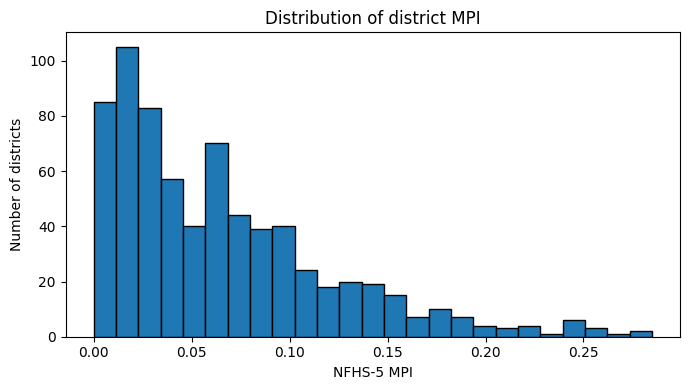

In [4]:
plt.figure(figsize=(7,4))
plt.hist(df[MPI_COL].dropna(), bins=25, edgecolor="black")
plt.xlabel("NFHS-5 MPI")
plt.ylabel("Number of districts")
plt.title("Distribution of district MPI")
plt.tight_layout()
plt.show()

## 5. Correlation of MPI with each health indicator

Pearson's r = linear association(Correlation Coefficient); Spearman's rho = rank-based (monotonic) association(Correlation Coefficient between ranks). Negative: higher-MPI districts tend to have lower values of that indicator.

In [5]:
rows = []
for col in HEALTH_COLS:
    pair = df[[MPI_COL, col]].dropna()
    r, p = pearsonr(pair[MPI_COL], pair[col])
    rho, _ = spearmanr(pair[MPI_COL], pair[col])
    rows.append({"Indicator": SHORT[col], "N": len(pair), "Pearson r": r,
                 "p-value": p, "Spearman rho": rho})
corr_table = pd.DataFrame(rows).sort_values("Pearson r").reset_index(drop=True)
display(corr_table.style.format({"Pearson r": "{:.3f}", "Spearman rho": "{:.3f}", "p-value": "{:.2e}"}))

,Indicator,N,Pearson r,p-value,Spearman rho
0,Menstrual hygiene,707,-0.483,1.28e-42,-0.501
1,Improved sanitation,707,-0.470,4.02e-40,-0.425
2,High blood sugar (men),707,-0.227,9.71e-10,-0.279
3,Full vaccination (card),685,-0.210,2.82e-08,-0.250
4,Adequate diet (6-23 mo),706,-0.178,2.03e-06,-0.227
5,Alcohol use (men),707,-0.104,5.53e-03,-0.140
6,Anaemia (women 15-49),707,0.099,8.11e-03,0.129
7,Tobacco use (women),707,0.191,3.08e-07,0.268


### Correlation plot

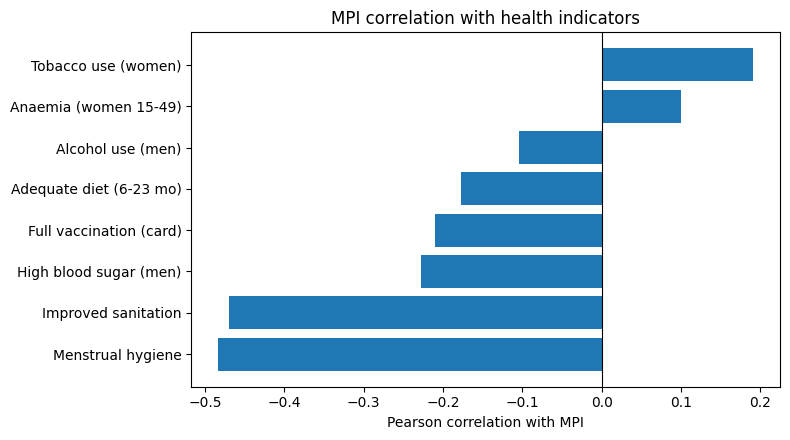

In [6]:
plt.figure(figsize=(8,4.5))
plt.barh(corr_table["Indicator"], corr_table["Pearson r"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with MPI")
plt.title("MPI correlation with health indicators")
plt.tight_layout()
plt.show()

**Results (from this file):**
Menstrual hygiene and sanitation have the strongest associations with MPI. Vaccination and diet are mildly negative, in the expected direction. Anaemia and tobacco use are weakly positive. Rank-based and linear measures agree in sign everywhere.

## 6. Scatterplots for the two strongest negative associations

The trendline is descriptive; it does not mean every district follows the same relationship. Look for clusters and influential points.

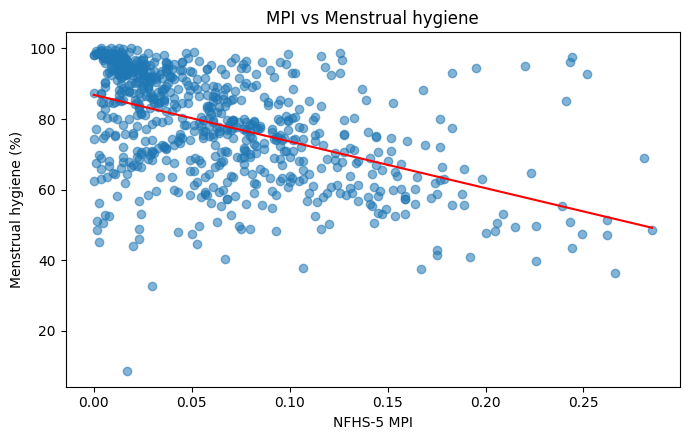

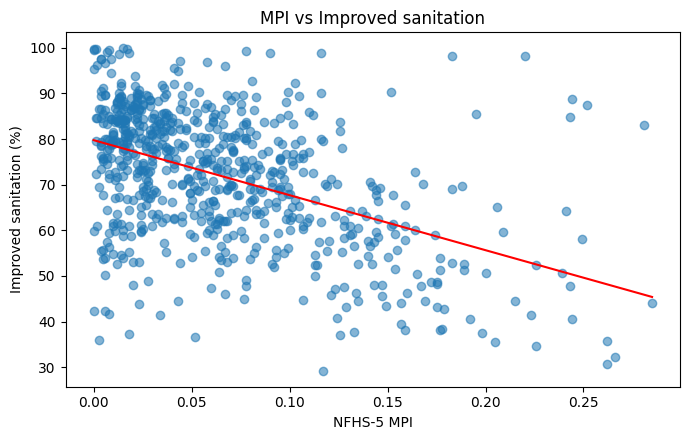

In [7]:
selected = [HEALTH_COLS[1], HEALTH_COLS[0]]   # menstrual hygiene, improved sanitation

for col in selected:
    pair = df[[MPI_COL, col]].dropna()
    x, y = pair[MPI_COL], pair[col]
    slope, intercept = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 100)
    plt.figure(figsize=(7,4.5))
    plt.scatter(x, y, alpha=0.55)
    plt.plot(xx, slope*xx + intercept, color="red")
    plt.xlabel("NFHS-5 MPI")
    plt.ylabel(SHORT[col] + " (%)")
    plt.title(f"MPI vs {SHORT[col]}")
    plt.tight_layout()
    plt.show()

## 7. Simple linear regression

Unadjusted fit for the two strongest correlations. Slope = average change in the indicator (percentage points) per 1.0 increase in MPI. MPI's range is well below 1, so a 0.1 increase (slope × 0.1) is easier to read.

Menstrual hygiene: slope ≈ −132.17 per 1.0 MPI (≈ −13.22 pp per 0.1 MPI), R² ≈ 0.233.  
Improved sanitation: slope ≈ −120.59 per 1.0 MPI (≈ −12.06 pp per 0.1 MPI), R² ≈ 0.221.

These are unadjusted associations, not causal effects.

In [8]:
for col in selected:
    pair = df[[MPI_COL, col]].dropna()
    fit = linregress(pair[MPI_COL], pair[col])
    print("\nOutcome:", SHORT[col])
    print(f"N = {len(pair)}")
    print(f"Slope per 1.0 MPI = {fit.slope:.3f}")
    print(f"Estimated change per 0.1 MPI = {fit.slope*0.1:.3f} percentage points")
    print(f"Intercept = {fit.intercept:.3f}")
    print(f"R-squared = {fit.rvalue**2:.3f}")
    print(f"p-value = {fit.pvalue:.3g}")
    print(f"Slope standard error = {fit.stderr:.3f}")


Outcome: Menstrual hygiene
N = 707
Slope per 1.0 MPI = -132.173
Estimated change per 0.1 MPI = -13.217 percentage points
Intercept = 86.858
R-squared = 0.233
p-value = 1.28e-42
Slope standard error = 9.022

Outcome: Improved sanitation
N = 707
Slope per 1.0 MPI = -120.593
Estimated change per 0.1 MPI = -12.059 percentage points
Intercept = 79.752
R-squared = 0.221
p-value = 4.02e-40
Slope standard error = 8.531


## 8. Interpretation and conclusions

### Findings
1. MPI is moderately negatively associated with menstrual hygiene (r ≈ −0.48) and improved sanitation (r ≈ −0.47).
2. Blood sugar (men), full vaccination and adequate diet show weaker negative associations (r ≈ −0.23, −0.21, −0.18).
3. Tobacco use (women, r ≈ +0.19) and anaemia (r ≈ +0.10) are weakly positive; alcohol use (men) is weakly negative (r ≈ −0.10).
4. The regression lines are descriptive; R² is ≈ 0.233 (menstrual hygiene) and ≈ 0.221 (sanitation), so most district-to-district variation is not explained by MPI alone.
5. Blood sugar and alcohol being lower in high-MPI districts is plausibly a reporting/lifestyle or age-structure effect; this needs a definition and confounder check before interpretation.

### Limitations
- Observational, cross-sectional district data cannot establish causality.
- District averages can hide within-district variation (ecological fallacy).
- Pairwise missingness: vaccination (n=685) and diet (n=706) use smaller samples.
- Possible confounding by state, urbanisation, education, age structure, etc.
- Confirm exact variable definitions and that MPI components do not overlap with the health indicator (e.g. sanitation is itself an MPI component, so its correlation with MPI is partly mechanical).
